# Rain tomorrow: baselines

Reference points that every model has to beat. They use the same split, folds and metrics as the model notebooks.

| Baseline | Probability / prediction |
|---|---|
| Always no rain | always 0 |
| Persistence | `RainToday`: rain tomorrow if it rained today (missing → no rain) |
| Climatology | share of rainy days for this station and calendar month, estimated on the training part only |

Persistence and "always no rain" have no tuning. Climatology is a probability, so like the models it gets a threshold chosen by F1 on the fourth validation year.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data_prep.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data_prep.py").exists():
    raise RuntimeError("Run from the repository root or models directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_prep import TARGET, load_clean, split_train_test, time_cv_splits

OUT = ROOT / "results" / "baseline"
OUT.mkdir(parents=True, exist_ok=True)

## Data and validation

In [2]:
df = load_clean(ROOT / "data" / "weatherAUS.csv")
train, gap, test = split_train_test(df)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
cv = time_cv_splits(train["Date"])
threshold_train, threshold_val = cv[-1]
print(f"train {len(train):,} | test {len(test):,} | test rain share {test[TARGET].mean():.4f}")

train 124,858 | test 17,286 | test rain share 0.2317


## Helpers

In [3]:
def metrics(y_true, probability, threshold=0.5):
    prediction = probability >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y_true, prediction),
                specificity=tn / (tn + fp) if tn + fp else np.nan,
                precision=precision_score(y_true, prediction, zero_division=0),
                recall=recall_score(y_true, prediction, zero_division=0),
                f1=f1_score(y_true, prediction, zero_division=0),
                average_precision=average_precision_score(y_true, probability),
                roc_auc=roc_auc_score(y_true, probability))


def f1_threshold(y_true, probability):
    precision, recall, thresholds = precision_recall_curve(y_true, probability)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)
    return float(thresholds[np.flatnonzero(f1 == f1.max())[-1]])


def always_no(fit_part, part):
    return np.zeros(len(part))


def persistence(fit_part, part):
    return part["RainToday"].fillna(0).to_numpy()


def climatology(fit_part, part):
    key = lambda d: list(zip(d["Location"], d["Date"].dt.month))
    rates = fit_part.groupby([fit_part["Location"], fit_part["Date"].dt.month])[TARGET].mean()
    by_station = fit_part.groupby("Location")[TARGET].mean()
    p = pd.Series(key(part)).map(rates.to_dict())
    p = p.fillna(part["Location"].reset_index(drop=True).map(by_station)).fillna(fit_part[TARGET].mean())
    return p.to_numpy()


BASELINES = {"Always no rain": always_no, "Persistence (RainToday)": persistence, "Climatology (station × month)": climatology}

## Validation folds

Folds 1–3 are the model-selection years, fold 4 is the threshold year. For a constant prediction AP equals the rain share and ROC-AUC equals 0.5.

In [4]:
rows = []
for name, predict in BASELINES.items():
    for k, (tr, va) in enumerate(cv, 1):
        p = predict(train.iloc[tr], train.iloc[va])
        rows.append(dict(baseline=name, fold=k, **metrics(train[TARGET].iloc[va], p)))
cv_metrics = pd.DataFrame(rows)
cv_metrics["role"] = np.where(cv_metrics.fold == len(cv), "threshold validation", "model selection")
display(cv_metrics.groupby(["baseline", "role"])[["precision", "recall", "f1", "average_precision", "roc_auc"]].mean().round(4))
cv_metrics.to_csv(OUT / "cv_metrics.csv", index=False)

precision  recall      f1  \
baseline                      role                                              
Always no rain                model selection          0.0000  0.0000  0.0000   
                              threshold validation     0.0000  0.0000  0.0000   
Climatology (station × month) model selection          0.5006  0.0889  0.1509   
                              threshold validation     0.4528  0.0706  0.1221   
Persistence (RainToday)       model selection          0.4498  0.4432  0.4464   
                              threshold validation     0.4484  0.4428  0.4456   

                                                    average_precision  roc_auc  
baseline                      role                                              
Always no rain                model selection                  0.2106   0.5000  
                              threshold validation             0.2115   0.5000  
Climatology (station × month) model selection                  0.3464   0.6674  
                              threshold validation             0.3238   0.6505  
Persistence (RainToday)       model selection                  0.3167   0.6493  
                              threshold validation             0.3164   0.6484

## Threshold for climatology (fold 4)

In [5]:
p_val = climatology(train.iloc[threshold_train], train.iloc[threshold_val])
CLIM_THRESHOLD = f1_threshold(train[TARGET].iloc[threshold_val], p_val)
print(f"Climatology F1 threshold on fold 4: {CLIM_THRESHOLD:.4f}")

Climatology F1 threshold on fold 4: 0.1989


## Test

In [6]:
y_test = test[TARGET]
p_clim = climatology(train, test)
test_metrics = pd.DataFrame([
    dict(baseline="Always no rain", threshold=0.5, **metrics(y_test, always_no(train, test))),
    dict(baseline="Persistence (RainToday)", threshold=0.5, **metrics(y_test, persistence(train, test))),
    dict(baseline="Climatology (station × month)", threshold=0.5, **metrics(y_test, p_clim)),
    dict(baseline="Climatology (station × month)", threshold=CLIM_THRESHOLD, **metrics(y_test, p_clim, CLIM_THRESHOLD)),
])
display(test_metrics.round(4))
test_metrics.to_csv(OUT / "test_metrics.csv", index=False)
print(f"Test rain prevalence: {y_test.mean():.4f}")

,baseline,threshold,accuracy,specificity,precision,recall,f1,average_precision,roc_auc
0,Always no rain,0.5000,0.7683,1.0000,0.0000,0.0000,0.0000,0.2317,0.5000
1,Persistence (RainToday),0.5000,0.7446,0.8354,0.4485,0.4438,0.4462,0.3280,0.6396
2,Climatology (station × month),0.5000,0.7706,0.9838,0.5435,0.0639,0.1144,0.3698,0.6572
3,Climatology (station × month),0.1989,0.5539,0.5094,0.3013,0.7012,0.4215,0.3698,0.6572


Test rain prevalence: 0.2317


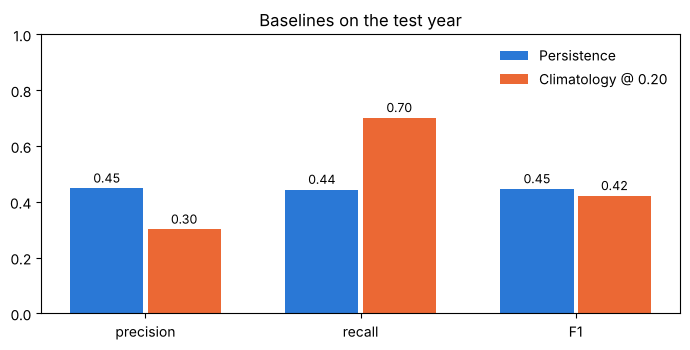

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
plot = test_metrics.iloc[[1, 3]].assign(label=["Persistence", f"Climatology @ {CLIM_THRESHOLD:.2f}"])
x = np.arange(3)
for i, (_, r) in enumerate(plot.iterrows()):
    bars = ax.bar(x + (i - 0.5) * 0.36, [r.precision, r.recall, r.f1], width=0.34, label=r.label,
                  color=["#2a78d6", "#eb6834"][i])
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
ax.set_xticks(x, ["precision", "recall", "F1"])
ax.set(ylim=(0, 1), title="Baselines on the test year")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Takeaways (test year)**

| Baseline | F1 | Precision | Recall | AP | ROC-AUC |
|---|---|---|---|---|---|
| Always no rain | 0.000 | — | 0.000 | 0.232 | 0.500 |
| Persistence (`RainToday`) | **0.446** | 0.449 | 0.444 | 0.328 | 0.640 |
| Climatology @ 0.199 | 0.422 | 0.301 | 0.701 | **0.370** | **0.657** |

- "Always no rain" reaches 76.8% accuracy on the test year with zero recall, which is why accuracy is not used to compare models.
- **Persistence is the F1 reference** (0.446): only about 45% of rainy days follow another rainy day.
- **Climatology is the AP / ROC-AUC reference** (0.370 / 0.657): knowing only the station and month already ranks days better than chance, but it cannot say which day in that month will be wet.
- Any model worth reporting should beat both: F1 above 0.45 and AP above 0.37 on the test year.